# Exercise 1: K-means Clustering on Iris

En este ejercicio se aplica *K-means clustering* al dataset Iris: 150 observaciones, cuatro variables numéricas y tres especies. Se realiza primero una partición estratificada 80/20; el algoritmo y el mapeo de clusters se ajustan exclusivamente con el conjunto de entrenamiento, antes de evaluar el hold-out, para evitar *data leakage*.

### 1. Setup & Data Split

Se carga el archivo `iris.csv` (sin encabezado) y se separan predictores y etiquetas. En Google Colab, sube `iris.csv` al entorno antes de ejecutar; si no está disponible, la función utiliza el dataset Iris incluido en scikit-learn.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, adjusted_rand_score


def load_iris(path):
    """Load the Iris CSV, or fall back to scikit-learn's bundled dataset.

    Args:
        path (str): Path to a headerless CSV with four measurements and species.

    Returns:
        tuple: X, a DataFrame of four numeric features, and y, a Series of species.
    """
    columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
    try:
        data = pd.read_csv(path, header=None, names=columns)
    except FileNotFoundError:
        from sklearn.datasets import load_iris as sklearn_load_iris

        iris = sklearn_load_iris()
        X_fallback = pd.DataFrame(iris.data, columns=columns[:4])
        species_names = np.array(["Iris-setosa", "Iris-versicolor", "Iris-virginica"])
        y_fallback = pd.Series(species_names[iris.target], name="species")
        return X_fallback, y_fallback

    X = data[columns[:4]].astype(float)
    y = data["species"].astype(str)
    return X, y


X, y = load_iris("iris.csv")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
pd.concat([X_test, y_test], axis=1).to_csv("iris_test_20.csv", index=False)

print(f"Dataset: {X.shape[0]} rows × {X.shape[1]} features")
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")
print("Training labels:")
print(y_train.value_counts().sort_index())

Dataset: 150 rows × 4 features
Train: 120 rows | Test: 30 rows
Training labels:
species
Iris-setosa        40
Iris-versicolor    40
Iris-virginica     40
Name: count, dtype: int64


### 2. Elbow Method: Choosing K

Se calcula la *inertia* para varios valores de K ajustando cada modelo únicamente sobre `X_train`. La inertia es la suma de distancias cuadráticas dentro de cada cluster; se busca el punto de inflexión (*elbow*).

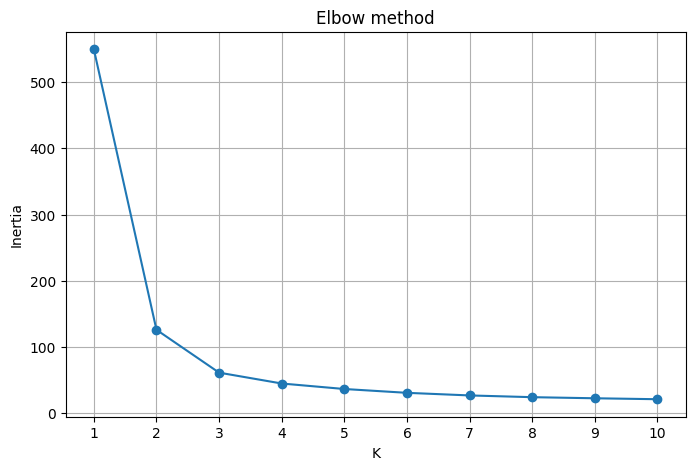

In [2]:
def elbow_curve(X_fit, k_max=10):
    """Compute K-means inertia for candidate cluster counts.

    Args:
        X_fit (array-like): Training features used to fit each K-means model.
        k_max (int): Maximum number of clusters to evaluate, starting at 1.

    Returns:
        list: Inertia values for K=1 through K=k_max.
    """
    inertias = []
    for k in range(1, k_max + 1):
        model = KMeans(n_clusters=k, n_init=10, random_state=42)
        model.fit(X_fit)
        inertias.append(model.inertia_)
    return inertias


inertias = elbow_curve(X_train, k_max=10)
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel('K')
plt.ylabel('Inertia')
plt.title('Elbow method')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

**Key Insights**

- La caída es pronunciada hasta K=3 (aproximadamente 550 → 125 → 60) y luego la curva se aplana.
- El *elbow* en K=3 es consistente con las tres especies reales.
- K=2 también presenta un quiebre: *setosa* está muy separada, mientras *versicolor* y *virginica* tienen regiones de características solapadas.

### 3. Cluster-to-Class Mapping via Majority Vote

Se fija K=3 y se ajusta K-means solo con las observaciones de entrenamiento. Para poder comparar sus asignaciones con etiquetas de especie, cada cluster se asocia con la clase más frecuente (*majority vote*) dentro de ese cluster en el conjunto de entrenamiento.

In [3]:
K_OPT = 3
kmeans = KMeans(n_clusters=K_OPT, n_init=10, random_state=42).fit(X_train)
train_clusters = pd.Series(kmeans.labels_, index=y_train.index, name="cluster")
cluster_to_species = (
    pd.DataFrame({"cluster": train_clusters, "species": y_train})
    .groupby("cluster")["species"]
    .agg(lambda species: species.mode().iloc[0])
    .to_dict()
)
print("Cluster-to-species mapping:", cluster_to_species)

Cluster-to-species mapping: {0: 'Iris-setosa', 1: 'Iris-versicolor', 2: 'Iris-virginica'}


Los índices asignados por K-means son arbitrarios: el cluster 0 no tiene por qué representar *setosa* (ni seguir el orden de las clases). El voto mayoritario usa las etiquetas únicamente después del ajuste no supervisado, para dar una interpretación semántica a cada grupo.

### 4. Evaluation on the 20% Hold-out Set

Se predicen los clusters del conjunto de prueba y se traducen a especies usando el mapeo aprendido en entrenamiento. Se reportan *accuracy*, *Adjusted Rand Index* (ARI) y la tabla de contingencia entre especie real y cluster predicho.

In [4]:
test_clusters = kmeans.predict(X_test)
y_pred = pd.Series(test_clusters, index=y_test.index).map(cluster_to_species)

accuracy = accuracy_score(y_test, y_pred)
ari = adjusted_rand_score(y_test, test_clusters)
print(f"Accuracy: {accuracy:.2f} ({(y_test == y_pred).sum()}/{len(y_test)})")
print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print("\nContingency table (true species × predicted cluster):")
print(pd.crosstab(y_test, test_clusters, rownames=["True species"], colnames=["Predicted cluster"]))

Accuracy: 0.90 (27/30)
Adjusted Rand Index (ARI): 0.7267

Contingency table (true species × predicted cluster):
Predicted cluster   0  1  2
True species               
Iris-setosa        10  0  0
Iris-versicolor     0  9  1
Iris-virginica      0  2  8


**Expected results (random_state=42)**

| Metric | Result |
|---|---:|
| Accuracy (majority-vote species mapping) | 0.90 (27/30) |
| Adjusted Rand Index (ARI) | 0.727 (approximately 0.7267) |

**Key Insights**

- *Setosa* se identifica perfectamente: 10/10 observaciones.
- Los tres errores restantes se producen entre *versicolor* y *virginica*: 2 *virginica* quedan en el cluster 1 y 1 *versicolor* en el cluster 2 (los identificadores reflejan el ajuste determinista de este ejemplo).
- ARI mide concordancia entre particiones, corrigiendo por acuerdo esperado al azar: 0 equivale aproximadamente al azar y 1 a concordancia perfecta.
- Con solo 30 observaciones de prueba, cada error cambia el *accuracy* en aproximadamente 3.3 puntos porcentuales.

### 5. Comparison with KNN

| Aspect | K-means | K-nearest neighbors (KNN) |
|---|---|---|
| Tipo de aprendizaje | No supervisado; las etiquetas solo se usan después para nombrar los clusters | Supervisado |
| Uso de etiquetas | No se usan para ajustar los centroides | Se usan durante el entrenamiento |
| Regla para un punto nuevo | Asignación al centroide más cercano | Voto de los K vecinos más cercanos |
| Similitud | Ambos métodos se basan en distancia euclidiana en su forma estándar | Ambos métodos se basan en distancia euclidiana en su forma estándar |

## Exercise 2: Gaussian Mixture Model (GMM) on Iris
### 1. Optimal Number of Components via Prediction Strength
Se utilizó la **prediction strength** (Tibshirani & Walther) para elegir K. Para cada K, se divide el set de entrenamiento en dos mitades (A y B), se ajusta un GMM en cada una y se mide qué fracción de pares de puntos de B que comparten cluster según el modelo de B también lo comparten según el modelo de A. Se reporta el mínimo entre clusters, promediado sobre 10 splits aleatorios, y se selecciona el mayor K con ps >= 0.8.
**Key Insights**
- ps = 1.0 para K = 1 y K = 2, y cae a 0.616 para K = 3 (por debajo del umbral de 0.8).
- Setosa está claramente separada, mientras que **versicolor y virginica se solapan** en el espacio de features. Con K = 3, los modelos de A y B parten esa región de forma distinta, por lo que la partición es **inestable**.
- Estabilidad no implica utilidad: K = 2 es el clustering más reproducible, pero no recupera las 3 especies.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.mixture import GaussianMixture
from sklearn.metrics import accuracy_score, adjusted_rand_score

COLS = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
df = pd.read_csv("iris.csv", header=None, names=COLS)
X, y = df[COLS[:4]], df["species"]

# Split BEFORE any fitting to avoid data leakage (same split as Exercise 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
pd.concat([X_test, y_test], axis=1).to_csv("iris_test_20.csv", index=False)
Xtr = X_train.to_numpy()


def prediction_strength(X, k, n_repeats=10, seed=42):
    """Estimate prediction strength for a GMM with k components.

    Args:
        X (array-like): Training observations used for repeated half-splits.
        k (int): Number of Gaussian mixture components.
        n_repeats (int): Number of random half-splits to evaluate.
        seed (int): Base random seed for reproducible splits and models.

    Returns:
        float: Mean minimum within-cluster prediction strength over splits.
    """
    scores = []
    for r in range(n_repeats):
        Xa, Xb = train_test_split(
            X, test_size=0.5, random_state=seed + r
        )
        gm_a = GaussianMixture(
            n_components=k, n_init=5, random_state=seed
        ).fit(Xa)
        gm_b = GaussianMixture(
            n_components=k, n_init=5, random_state=seed
        ).fit(Xb)
        labels_b = gm_b.predict(Xb)
        labels_a_on_b = gm_a.predict(Xb)
        fractions = []
        for j in range(k):
            idx = np.where(labels_b == j)[0]
            n_j = len(idx)
            if n_j < 2:
                continue
            same = sum(
                np.sum(labels_a_on_b[idx] == labels_a_on_b[i]) - 1
                for i in idx
            )
            fractions.append(same / (n_j * (n_j - 1)))
        scores.append(min(fractions) if fractions else 0.0)
    return float(np.mean(scores))


k_range = range(1, 9)
ps_values = [prediction_strength(Xtr, k) for k in k_range]

plt.figure(figsize=(8, 5))
plt.plot(k_range, ps_values, marker="o", label="Prediction strength")
plt.axhline(0.8, color="red", linestyle="--", label="Threshold = 0.8")
plt.xlabel("K (number of components)")
plt.ylabel("Prediction strength")
plt.title("Prediction strength (GMM)")
plt.xticks(list(k_range))
plt.legend()
plt.grid(True)
plt.show()

THRESHOLD = 0.8
K_OPT = max(k for k, ps in zip(k_range, ps_values) if ps >= THRESHOLD)
print("ps por K:", dict(zip(k_range, np.round(ps_values, 3))))
print("K óptimo:", K_OPT)

### 2. Final Model, Majority Vote & Evaluation
Se ajustó el GMM con K = 2 sobre el 80 % de entrenamiento y se asignó a cada cluster la especie mayoritaria (*majority vote*, calculado solo en train). Luego se clasificó el 20 % de test.
**Key Insights**
- Mapeo: `{0: Iris-setosa, 1: Iris-versicolor}`. Con solo 2 clusters, **Iris-virginica nunca puede ser predicha**, por lo que el accuracy máximo teórico es 20/30 ≈ 66.7 %.
- Resultados: **Accuracy = 0.667**, **ARI = 0.554**. El modelo alcanzó su techo teórico, pero ese techo es bajo.
- Comparado con K-means (K = 3, accuracy 0.90, ARI 0.73), el GMM con K = 2 es más *estable* pero menos *útil* si el objetivo es recuperar las 3 especies. Si ese es el objetivo, conviene usar K = 3 aun con menor estabilidad, o apoyarse en otros criterios (BIC/AIC, silhouette).

In [ ]:
gmm = GaussianMixture(n_components=K_OPT, n_init=10, random_state=42).fit(X_train)
train_clusters = gmm.predict(X_train)
cluster_to_species = (
    pd.DataFrame({"cluster": train_clusters, "species": y_train.values})
    .groupby("cluster")["species"]
    .agg(lambda s: s.mode().iloc[0])
    .to_dict()
)
print("Mapeo cluster -> especie:", cluster_to_species)
test_clusters = gmm.predict(X_test)
y_pred = pd.Series(test_clusters, index=y_test.index).map(cluster_to_species)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ARI     :", adjusted_rand_score(y_test, test_clusters))
print(pd.crosstab(pd.Series(test_clusters, name="cluster", index=y_test.index), y_test))